<a href="https://colab.research.google.com/github/munnamia1945/AI_ML_DL_CYS_Projects/blob/main/08-sentiment-analysis/sentiment_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Cell 1 - Project information

In [ ]:
# ============================================================
# PROJECT 08: SENTIMENT ANALYSIS
# TF-IDF + Logistic Regression vs Pretrained Transformer
# ============================================================

# Project Information
PROJECT_NUMBER = "08"
PROJECT_NAME = "Sentiment Analysis"

PROJECT_DESCRIPTION = """
This project compares two Natural Language Processing (NLP)
approaches for binary sentiment classification:

1. Traditional Machine Learning:
   TF-IDF + Logistic Regression

2. Pretrained Transformer:
   DistilBERT from Hugging Face Transformers

The objective is to classify movie reviews as Positive or Negative
and compare both approaches using the same test dataset.
"""

# Dataset Configuration
DATASET_NAME = "IMDb Movie Reviews"
DATASET_ID = "stanfordnlp/imdb"

TEXT_COLUMN = "text"
LABEL_COLUMN = "label"

CLASS_NAMES = {
    0: "Negative",
    1: "Positive"
}

NUM_CLASSES = len(CLASS_NAMES)

# Model Configuration
TRADITIONAL_MODEL_NAME = "TF-IDF + Logistic Regression"
TRANSFORMER_MODEL_NAME = "distilbert/distilbert-base-uncased"

# Experiment Configuration
RANDOM_STATE = 42
VALIDATION_SIZE = 0.10
MAX_SEQUENCE_LENGTH = 256

# Transformer Training Configuration
TRANSFORMER_EPOCHS = 2
TRANSFORMER_LEARNING_RATE = 2e-5
TRAIN_BATCH_SIZE = 16
EVAL_BATCH_SIZE = 32

# Evaluation Metrics
EVALUATION_METRICS = [
    "Accuracy",
    "Precision (Macro)",
    "Recall (Macro)",
    "F1-score (Macro)"
]

# Output Configuration
OUTPUT_DIR = "project08_outputs"

OUTPUT_FILES = [
    "model_comparison.csv",
    "test_predictions.csv",
    "tfidf_logistic_regression.joblib",
    "distilbert_model/",
    "project_summary.json"
]

# Reproducibility
import os
import random
import numpy as np

os.environ["PYTHONHASHSEED"] = str(RANDOM_STATE)

random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)

# Display Project Information
print("=" * 65)
print(f"PROJECT {PROJECT_NUMBER}: {PROJECT_NAME.upper()}")
print("=" * 65)

print("\nPROJECT DESCRIPTION")
print(PROJECT_DESCRIPTION.strip())

print("\nDATASET INFORMATION")
print("Dataset:", DATASET_NAME)
print("Dataset ID:", DATASET_ID)
print("Number of classes:", NUM_CLASSES)
print("Class labels:", CLASS_NAMES)

print("\nMODELS TO BE COMPARED")
print("Model 1:", TRADITIONAL_MODEL_NAME)
print("Model 2:", TRANSFORMER_MODEL_NAME)

print("\nEXPERIMENT CONFIGURATION")
print("Random state:", RANDOM_STATE)
print("Validation split:", f"{VALIDATION_SIZE:.0%}")
print("Maximum sequence length:", MAX_SEQUENCE_LENGTH)
print("Transformer epochs:", TRANSFORMER_EPOCHS)
print("Transformer learning rate:", TRANSFORMER_LEARNING_RATE)
print("Training batch size:", TRAIN_BATCH_SIZE)
print("Evaluation batch size:", EVAL_BATCH_SIZE)

print("\nEVALUATION METRICS")
for metric in EVALUATION_METRICS:
    print("-", metric)

print("\nOUTPUT DIRECTORY")
print(OUTPUT_DIR)

print("\nPROJECT INITIALIZATION COMPLETED")
print("=" * 65)

PROJECT 08: SENTIMENT ANALYSIS

PROJECT DESCRIPTION
This project compares two Natural Language Processing (NLP)
approaches for binary sentiment classification:

1. Traditional Machine Learning:
   TF-IDF + Logistic Regression

2. Pretrained Transformer:
   DistilBERT from Hugging Face Transformers

The objective is to classify movie reviews as Positive or Negative
and compare both approaches using the same test dataset.

DATASET INFORMATION
Dataset: IMDb Movie Reviews
Dataset ID: stanfordnlp/imdb
Number of classes: 2
Class labels: {0: 'Negative', 1: 'Positive'}

MODELS TO BE COMPARED
Model 1: TF-IDF + Logistic Regression
Model 2: distilbert/distilbert-base-uncased

EXPERIMENT CONFIGURATION
Random state: 42
Validation split: 10%
Maximum sequence length: 256
Transformer epochs: 2
Transformer learning rate: 2e-05
Training batch size: 16
Evaluation batch size: 32

EVALUATION METRICS
- Accuracy
- Precision (Macro)
- Recall (Macro)
- F1-score (Macro)

OUTPUT DIRECTORY
project08_outputs

PROJ

### Cell 2 - Install libraries

In [ ]:
%pip -q install transformers datasets accelerate scikit-learn pandas matplotlib seaborn

### Cell 3 - Import libraries and check hardware

In [ ]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch

from datasets import load_dataset
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

print("PyTorch version:", torch.__version__)
print("Device:", DEVICE)

if DEVICE == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch version: 2.11.0+cu130
Device: cuda
GPU: Tesla T4


### Cell 4 - Load IMDb dataset

The IMDb dataset contains 50,000 labeled movie reviews. First, we will examine the dataset structure and label distribution.

In [ ]:
dataset = load_dataset("stanfordnlp/imdb")

print(dataset)
print("\nTraining samples:", len(dataset["train"]))
print("Test samples:", len(dataset["test"]))

train_df = pd.DataFrame(dataset["train"])
test_df = pd.DataFrame(dataset["test"])

print("\nTraining data preview:")
display(train_df.head())

print("\nLabel distribution:")
display(
    train_df["label"]
    .value_counts()
    .sort_index()
    .rename(index={0: "Negative", 1: "Positive"})
    .to_frame("count")
)

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    unsupervised: Dataset({
        features: ['text', 'label'],
        num_rows: 50000
    })
})

Training samples: 25000
Test samples: 25000

Training data preview:


,text,label
0,I rented I AM CURIOUS-YELLOW from my video sto...,0
1,"""I Am Curious: Yellow"" is a risible and preten...",0
2,If only to avoid making this type of film in t...,0
3,This film was probably inspired by Godard's Ma...,0
4,"Oh, brother...after hearing about this ridicul...",0



Label distribution:


,count
label,
Negative,12500
Positive,12500


### Cell 5 - Prepare training and validation data
A validation set will be separated from the training set. The test set will not be used for model selection or hyperparameter tuning.

In [ ]:
train_texts, val_texts, y_train, y_val = train_test_split(
    train_df["text"].astype(str).tolist(),
    train_df["label"].astype(int).to_numpy(),
    test_size=0.10,
    random_state=SEED,
    stratify=train_df["label"]
)

test_texts = test_df["text"].astype(str).tolist()
y_test = test_df["label"].astype(int).to_numpy()

print("Training samples:", len(train_texts))
print("Validation samples:", len(val_texts))
print("Test samples:", len(test_texts))

Training samples: 22500
Validation samples: 2500
Test samples: 25000


### Cell 6 — Train TF-IDF + Logistic Regression

In [ ]:
tfidf_model = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            max_features=50000,
            ngram_range=(1, 2),
            min_df=2,
            strip_accents="unicode",
            sublinear_tf=True
        )
    ),
    (
        "classifier",
        LogisticRegression(
            max_iter=1000,
            random_state=SEED
        )
    )
])

tfidf_model.fit(train_texts, y_train)

val_pred_tfidf = tfidf_model.predict(val_texts)

print("TF-IDF model training completed.")
print(
    "Validation accuracy:",
    round(accuracy_score(y_val, val_pred_tfidf), 4)
)
print(
    "Validation F1-score:",
    round(f1_score(y_val, val_pred_tfidf, average="macro"), 4)
)

TF-IDF model training completed.
Validation accuracy: 0.8992
Validation F1-score: 0.8992


### Cell 7 - Load pretrained DistilBERT

In [ ]:
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    DataCollatorWithPadding,
    TrainingArguments,
    Trainer
)

MODEL_NAME = "distilbert/distilbert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

transformer_model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2
)

print("Pretrained model:", MODEL_NAME)
print("Device:", DEVICE)

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Pretrained model: distilbert/distilbert-base-uncased
Device: cuda


### Cell 8 - Tokenize the dataset

In [ ]:
# Replace Cell 8 with this version

from datasets import Dataset

train_transformer_df = pd.DataFrame({
    "text": train_texts,
    "labels": y_train
})

val_transformer_df = pd.DataFrame({
    "text": val_texts,
    "labels": y_val
})

test_transformer_df = pd.DataFrame({
    "text": test_texts,
    "labels": y_test
})

transformer_train = Dataset.from_pandas(
    train_transformer_df, preserve_index=False
)
transformer_val = Dataset.from_pandas(
    val_transformer_df, preserve_index=False
)
transformer_test = Dataset.from_pandas(
    test_transformer_df, preserve_index=False
)

def tokenize_batch(batch):
    return tokenizer(
        batch["text"],
        truncation=True,
        max_length=MAX_LENGTH
    )

transformer_train = transformer_train.map(
    tokenize_batch, batched=True
)
transformer_val = transformer_val.map(
    tokenize_batch, batched=True
)
transformer_test = transformer_test.map(
    tokenize_batch, batched=True
)

columns = ["input_ids", "attention_mask", "labels"]

transformer_train.set_format("torch", columns=columns)
transformer_val.set_format("torch", columns=columns)
transformer_test.set_format("torch", columns=columns)

data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

print("Transformer train:", len(transformer_train))
print("Transformer validation:", len(transformer_val))
print("Transformer test:", len(transformer_test))

Map:   0%|          | 0/22500 [00:00<?, ? examples/s]

Map:   0%|          | 0/2500 [00:00<?, ? examples/s]

Map:   0%|          | 0/25000 [00:00<?, ? examples/s]

Transformer train: 22500
Transformer validation: 2500
Transformer test: 25000


### Cell 9 - Fine-tune DistilBERT

In [ ]:
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)

    return {
        "accuracy": accuracy_score(labels, predictions),
        "precision_macro": precision_score(
            labels, predictions, average="macro", zero_division=0
        ),
        "recall_macro": recall_score(
            labels, predictions, average="macro", zero_division=0
        ),
        "f1_macro": f1_score(
            labels, predictions, average="macro", zero_division=0
        )
    }

training_args = TrainingArguments(
    output_dir="project08_outputs/distilbert_checkpoints",
    num_train_epochs=2,
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="f1_macro",
    greater_is_better=True,
    logging_steps=100,
    report_to="none",
    seed=SEED,
    fp16=torch.cuda.is_available()
)

trainer = Trainer(
    model=transformer_model,
    args=training_args,
    train_dataset=transformer_train,
    eval_dataset=transformer_val,
    processing_class=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics
)

trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy,Precision Macro,Recall Macro,F1 Macro
1,0.263163,0.249331,0.900400,0.900790,0.900400,0.900376
2,0.160491,0.293718,0.907600,0.907715,0.907600,0.907593


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=2814, training_loss=0.23648482099355495, metrics={'train_runtime': 338.8915, 'train_samples_per_second': 132.786, 'train_steps_per_second': 8.304, 'total_flos': 2980516469760000.0, 'train_loss': 0.23648482099355495, 'epoch': 2.0})

### Cell 10 - Evaluate both models on the test set

In [ ]:
# Traditional ML model
tfidf_pred = tfidf_model.predict(test_texts)

# Fine-tuned Transformer
transformer_output = trainer.predict(transformer_test)
transformer_pred = np.argmax(
    transformer_output.predictions, axis=-1
)

def calculate_metrics(y_true, y_pred, model_name):
    return {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision (Macro)": precision_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "Recall (Macro)": recall_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "F1-score (Macro)": f1_score(
            y_true, y_pred, average="macro", zero_division=0
        )
    }

results_df = pd.DataFrame([
    calculate_metrics(y_test, tfidf_pred, "TF-IDF + Logistic Regression"),
    calculate_metrics(y_test, transformer_pred, "Fine-tuned DistilBERT")
])

display(results_df.round(4))

,Model,Accuracy,Precision (Macro),Recall (Macro),F1-score (Macro)
0,TF-IDF + Logistic Regression,0.8984,0.8984,0.8984,0.8984
1,Fine-tuned DistilBERT,0.9108,0.9110,0.9108,0.9107


### Cell 11 - Compare model performance

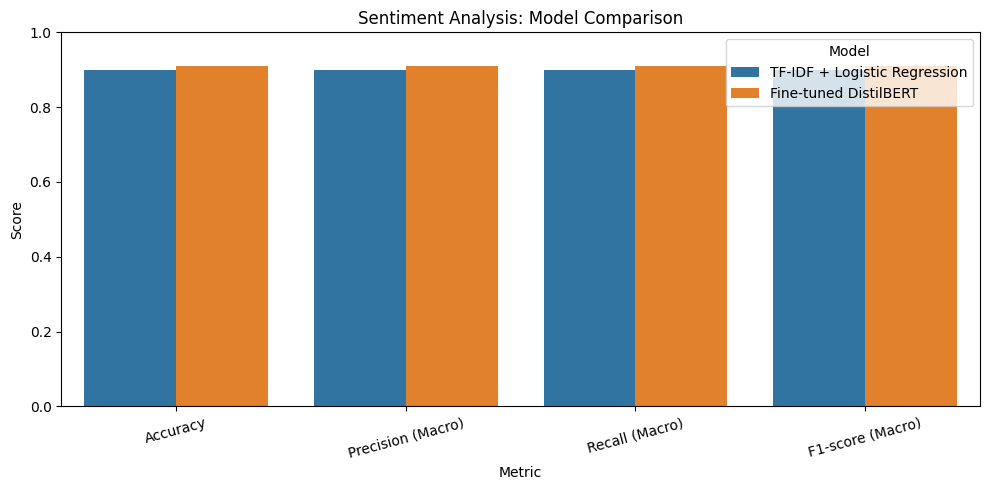

In [ ]:
plt.figure(figsize=(10, 5))

plot_df = results_df.melt(
    id_vars="Model",
    var_name="Metric",
    value_name="Score"
)

sns.barplot(
    data=plot_df,
    x="Metric",
    y="Score",
    hue="Model"
)

plt.ylim(0, 1)
plt.title("Sentiment Analysis: Model Comparison")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

### Cell 12 - Classification reports

In [ ]:
print("TF-IDF + Logistic Regression")
print(classification_report(
    y_test,
    tfidf_pred,
    target_names=["Negative", "Positive"],
    zero_division=0
))

print("\nFine-tuned DistilBERT")
print(classification_report(
    y_test,
    transformer_pred,
    target_names=["Negative", "Positive"],
    zero_division=0
))

TF-IDF + Logistic Regression
              precision    recall  f1-score   support

    Negative       0.90      0.89      0.90     12500
    Positive       0.89      0.90      0.90     12500

    accuracy                           0.90     25000
   macro avg       0.90      0.90      0.90     25000
weighted avg       0.90      0.90      0.90     25000


Fine-tuned DistilBERT
              precision    recall  f1-score   support

    Negative       0.92      0.90      0.91     12500
    Positive       0.90      0.92      0.91     12500

    accuracy                           0.91     25000
   macro avg       0.91      0.91      0.91     25000
weighted avg       0.91      0.91      0.91     25000



### Cell 13 - Confusion matrices

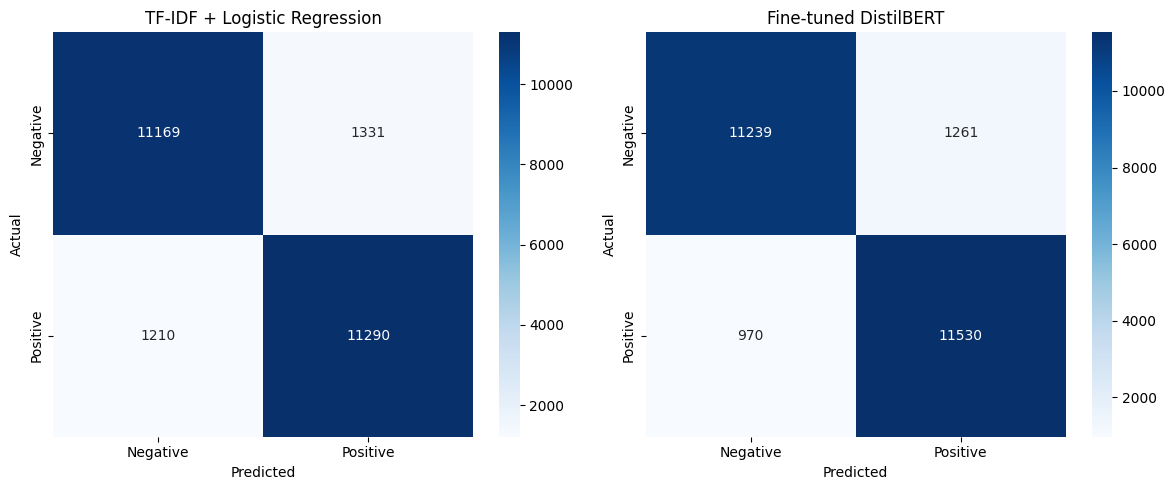

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, pred, title in [
    (axes[0], tfidf_pred, "TF-IDF + Logistic Regression"),
    (axes[1], transformer_pred, "Fine-tuned DistilBERT")
]:
    cm = confusion_matrix(y_test, pred)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Negative", "Positive"],
        yticklabels=["Negative", "Positive"],
        ax=ax
    )

    ax.set_title(title)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

### Cell 14 - Test custom reviews

In [ ]:
sample_reviews = [
    "This movie was fantastic. I really enjoyed every moment.",
    "The story was boring and the acting was disappointing.",
    "The movie was okay, but I expected something better."
]

tfidf_sample_pred = tfidf_model.predict(sample_reviews)

transformer_inputs = tokenizer(
    sample_reviews,
    return_tensors="pt",
    padding=True,
    truncation=True,
    max_length=MAX_LENGTH
)

transformer_model = trainer.model
transformer_model.eval()

transformer_inputs = {
    key: value.to(DEVICE)
    for key, value in transformer_inputs.items()
}

with torch.no_grad():
    outputs = transformer_model(**transformer_inputs)
    probs = torch.softmax(outputs.logits, dim=1)
    transformer_sample_pred = probs.argmax(dim=1).cpu().numpy()
    transformer_confidence = probs.max(dim=1).values.cpu().numpy()

for i, review in enumerate(sample_reviews):
    print("\nReview:", review)
    print(
        "TF-IDF:",
        "Positive" if tfidf_sample_pred[i] == 1 else "Negative"
    )
    print(
        "DistilBERT:",
        "Positive" if transformer_sample_pred[i] == 1 else "Negative",
        "| Confidence:",
        round(float(transformer_confidence[i]), 4)
    )


Review: This movie was fantastic. I really enjoyed every moment.
TF-IDF: Positive
DistilBERT: Positive | Confidence: 0.9942

Review: The story was boring and the acting was disappointing.
TF-IDF: Negative
DistilBERT: Negative | Confidence: 0.9946

Review: The movie was okay, but I expected something better.
TF-IDF: Negative
DistilBERT: Negative | Confidence: 0.9004


### Cell 15 - Export results and save models

In [ ]:
import joblib
import json

OUTPUT_DIR = "project08_outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

results_df.to_csv(
    f"{OUTPUT_DIR}/model_comparison.csv",
    index=False
)

pd.DataFrame({
    "text": test_texts,
    "true_label": y_test,
    "tfidf_prediction": tfidf_pred,
    "distilbert_prediction": transformer_pred
}).to_csv(
    f"{OUTPUT_DIR}/test_predictions.csv",
    index=False
)

joblib.dump(
    tfidf_model,
    f"{OUTPUT_DIR}/tfidf_logistic_regression.joblib"
)

trainer.save_model(f"{OUTPUT_DIR}/distilbert_model")
tokenizer.save_pretrained(f"{OUTPUT_DIR}/distilbert_model")

with open(f"{OUTPUT_DIR}/project_summary.json", "w") as f:
    json.dump({
        "project": PROJECT_NAME,
        "dataset": "IMDb",
        "test_samples": len(y_test),
        "models": results_df.to_dict(orient="records")
    }, f, indent=2)

print("Project outputs saved in:", OUTPUT_DIR)
print("Files:", os.listdir(OUTPUT_DIR))

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Project outputs saved in: project08_outputs
Files: ['model_comparison.csv', 'tfidf_logistic_regression.joblib', 'project_summary.json', 'distilbert_checkpoints', 'distilbert_model', 'test_predictions.csv']
